# Pronóstico seq2seq a 14 días con una WaveNet

Abordajes diarios en Chicago (CTA). En cada día de la ventana, una WaveNet predice los próximos 14 días de tren a partir de tren, bus y el tipo de día. Tiene seis partes:

1. Carga de datos
2. Series multivariadas
3. Series a tensores
4. Dataset con ventanas y DataLoaders
5. Entrenamiento de una WaveNet
6. Pronóstico en el conjunto de prueba

## 1. Carga de datos

Leemos el CSV de abordajes diarios, acortamos los nombres de las columnas y usamos la fecha como índice. Quitamos `total` (es la suma de bus y tren) y las filas duplicadas.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch import nn
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

In [ ]:
path = Path('CTA_-_Ridership_-_Daily_Boarding_Totals.csv')
df = pd.read_csv(path, parse_dates=["service_date"], thousands=",")
df.columns = ["date", "day_type", "bus", "rail", "total"]  # nombres cortos
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)  # total = bus + tren
df = df.drop_duplicates()  # meses duplicados: 2011-10 y 2014-07

## 2. Series multivariadas

La entrada usa tren y bus, en millones de abordajes, y el tipo de día siguiente en one-hot. Ese tipo se conoce de antemano.

In [ ]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

## 3. Series a tensores

Cada fila pasa a un tensor `float32` con las cinco columnas. Entrenamiento: 2016 a 2018. Validación: enero a mayo de 2019. Prueba: desde junio de 2019.

In [ ]:
train = torch.tensor(df_mulvar["2016-01-01":"2018-12-31"].values, dtype=torch.float32)
valid = torch.tensor(df_mulvar["2019-01-01":"2019-05-31"].values, dtype=torch.float32)    
test = torch.tensor(df_mulvar["2019-06-01":].values, dtype=torch.float32)

## 4. Dataset con ventanas y DataLoaders

`TimeSeriesDataset` arma pares de una ventana y el valor que sigue. `TimeSeriesDataset_multivariate` cambia el objetivo: en cada uno de los 56 días, los abordajes de tren de los 14 días siguientes. Los DataLoaders entregan esos pares en lotes de 32. El de entrenamiento se baraja; la validación conserva el orden.

In [ ]:
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, series, window_length):
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, idx):
        if idx >= len(self):
            raise IndexError("dataset index out of range")
        end = idx + self.window_length  # 1st index after window
        window = self.series[idx : end]
        target = self.series[end]
        return window, target

In [ ]:
class TimeSeriesDataset_multivariate(TimeSeriesDataset):
    def __init__(self, series, window_length, output_size):
        super().__init__(series, window_length)
        self.output_size = output_size
    
    def __len__(self):
        return len(self.series) - self.window_length - self.output_size + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx : end]
        target_period = self.series[idx + 1: end + self.output_size, 0]
        target = target_period.unfold(0, self.output_size, 1)
        return window, target

In [ ]:
train_set = TimeSeriesDataset_multivariate(train, 56, 14)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=32, shuffle=True)
valid_set = TimeSeriesDataset_multivariate(valid, 56, 14)
valid_loader = torch.utils.data.DataLoader(valid_set, batch_size=32, shuffle=False)

## 5. Entrenamiento de una WaveNet

La WaveNet lee la ventana de cinco variables y, en cada día, devuelve 14 días de tren. La pérdida de Huber usa todos esos pasos. Se entrena con Adam (`lr=0.001`) y 200 épocas. Cada 50 épocas se mide el MAPE en validación.

In [ ]:
import torch.nn.functional as F

class CausalConv1d(nn.Conv1d):
    def forward(self, x):
        padding = self.dilation[0] * (self.kernel_size[0] - 1)
        x = F.pad(x, (padding, 0))
        return super().forward(x)     

In [13]:
class WaveNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        layers = []
        for dilation in [1, 2, 4, 8, 16]:
            layers.append(CausalConv1d(input_size, hidden_size, kernel_size=2, dilation=dilation))
            layers.append(nn.ReLU())
            input_size = hidden_size
        self.convs = nn.Sequential(*layers)
        self.out = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        z = x.permute(0, 2, 1) # permute so channels are the last dimension
        z = self.convs(z) 
        z = z.permute(0, 2, 1) # put channels back first
        return self.out(z)

model = WaveNet(5, 32, 14).to(device)

In [15]:
import torch.nn as nn
import torchmetrics

loss_fn = nn.HuberLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
MAPE = torchmetrics.MeanAbsolutePercentageError().to(device)
n_epochs = 500

In [16]:
for epoch in range(n_epochs):
    model.train()
    total_loss = 0
    MAPE.reset()
    for batch in train_loader:
        window, target = batch
        window, target = window.to(device), target.to(device)
        pred = model(window)
        loss = loss_fn(pred, target)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    if epoch % 50 == 0:
        model.eval()
        with torch.no_grad():
            for window, target in valid_loader:
                window = window.to(device)
                target = target.to(device)
                pred = model(window)[:, -1] # only last prediction (14 day forecast at last day)
                MAPE.update(pred, target[:, -1])
        mean_loss = total_loss / len(train_loader)
        mape = MAPE.compute()
        print(f"Epoch {epoch+1}/{n_epochs}, Loss: {mean_loss:.4f}, MAPE: {mape:.4f}")

Epoch 1/500, Loss: 0.1558, MAPE: 0.6767
Epoch 51/500, Loss: 0.0029, MAPE: 0.0823
Epoch 101/500, Loss: 0.0027, MAPE: 0.0729
Epoch 151/500, Loss: 0.0026, MAPE: 0.0743
Epoch 201/500, Loss: 0.0024, MAPE: 0.0723
Epoch 251/500, Loss: 0.0023, MAPE: 0.0852
Epoch 301/500, Loss: 0.0022, MAPE: 0.0679
Epoch 351/500, Loss: 0.0021, MAPE: 0.0685
Epoch 401/500, Loss: 0.0021, MAPE: 0.0704
Epoch 451/500, Loss: 0.0020, MAPE: 0.0683


## 6. Pronóstico en el conjunto de prueba

La figura usa el pronóstico del último día de la primera ventana de prueba: los 14 días que siguen a la entrada. Muestra esa ventana de tren, el abordaje real y el pronóstico.

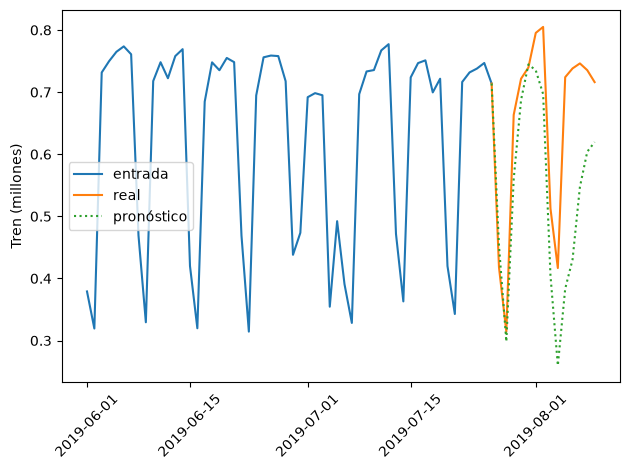

In [17]:
import matplotlib.pyplot as plt

test_set = TimeSeriesDataset_multivariate(test, 56, 14)
window, target = test_set[0]
model.eval()
with torch.no_grad():
    pred = model(window.unsqueeze(0).to(device)).cpu().squeeze(0)
forecast = pred[-1].numpy()   # pronóstico del último día
actual = target[-1].numpy()

dates = df_mulvar.loc["2019-06-01":].index[:70]
history = window[:, 0].numpy()
plt.plot(dates[:56], history, label="entrada")
plt.plot(dates[55:], np.r_[history[-1], actual], label="real")
plt.plot(dates[55:], np.r_[history[-1], forecast], ":", label="pronóstico")
plt.ylabel("Tren (millones)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()